In [58]:
# importo las librerias necesarias
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score


In [59]:
df_ent = pd.read_csv("../data/processed/pedidos_modelo.csv")
print(df_ent.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_state', 'customer_city', 'n_items', 'precio_total', 'flete_total', 'n_vendedores', 'peso_total_g', 'categoria', 'estado_vendedor', 'tarde', 'tarde_dia', 'mismo_estado', 'dias_prometidos', 'tramo_plazo', 'q_dias', 'peso_grupo', 'flete_grupo']


In [60]:
# Variables y target 

num_cols = ["dias_prometidos", "peso_total_g", "flete_total"]
cat_cols = ["customer_state", "estado_vendedor", "categoria"]
bin_cols = ["mismo_estado"]

X = df_ent[num_cols + cat_cols + bin_cols].copy()
y = df_ent["tarde_dia"].astype(int)
print(num_cols)
print(cat_cols)
print(bin_cols)

['dias_prometidos', 'peso_total_g', 'flete_total']
['customer_state', 'estado_vendedor', 'categoria']
['mismo_estado']


In [61]:
# Los 22 pesos en 0 son datos faltantes: los paso a NaN para imputarlos dentro del pipeline
X.loc[X["peso_total_g"] == 0, "peso_total_g"] = np.nan
X["mismo_estado"] = X["mismo_estado"].astype(int)

In [62]:
# Split estratificado 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print("% tarde train:", round(y_train.mean() * 100, 2), "| test:", round(y_test.mean() * 100, 2))


(77176, 7) (19294, 7)
% tarde train: 6.77 | test: 6.77


In [63]:
# Baseline: siempre predice "a tiempo"
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
pred = dummy.predict(X_test)
proba = dummy.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print("PR-AUC :", round(average_precision_score(y_test, proba), 3))

              precision    recall  f1-score   support

           0       0.93      1.00      0.96     17987
           1       0.00      0.00      0.00      1307

    accuracy                           0.93     19294
   macro avg       0.47      0.50      0.48     19294
weighted avg       0.87      0.93      0.90     19294

ROC-AUC: 0.5
PR-AUC : 0.068


In [64]:
# Preprocesamiento y primer pipeline 

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

# Numericas: rellenar faltantes con la mediana (los 22 pesos en NaN) y escalar
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Categoricas: rellenar faltantes y pasar a columnas 0/1.
# min_frequency=100 agrupa las categorias con menos de 100 pedidos en "infrequent"
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="desconocido")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100)),
])

# Une todo: cada grupo de columnas con su tratamiento; mismo_estado (0/1) pasa tal cual
preprocesador = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
    ("bin", "passthrough", bin_cols),
], sparse_threshold=0)

# Pipeline completo: preprocesar + modelo
pipe_lr = Pipeline([
    ("prep", preprocesador),
    ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

pipe_lr.fit(X_train, y_train)

pred = pipe_lr.predict(X_test)
proba = pipe_lr.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print("PR-AUC :", round(average_precision_score(y_test, proba), 3))

              precision    recall  f1-score   support

           0       0.96      0.67      0.79     17987
           1       0.12      0.63      0.20      1307

    accuracy                           0.67     19294
   macro avg       0.54      0.65      0.50     19294
weighted avg       0.90      0.67      0.75     19294

ROC-AUC: 0.702
PR-AUC : 0.147


In [65]:
%%time
# Ejecuto cross_validate con multiples métricas
# %%time me dice cuanto se tarda la celda entera en ejecutarse.
resultados = cross_validate(
    pipe_lr,
    X_train,
    y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring=["roc_auc", "average_precision"],
    return_train_score=True,
    n_jobs=1,
)

CPU times: user 1.18 s, sys: 33.9 ms, total: 1.21 s
Wall time: 1.03 s


In [66]:
# Leo los resultados

for metrica in ["roc_auc", "average_precision"]:
    for parte in ["train", "test"]:
        v = resultados[f"{parte}_{metrica}"]
        print(f"{parte:5} {metrica:18} media={v.mean():.3f}  std={v.std():.3f}")

# Veo que los valores estan correctos y no hay mucha std.

train roc_auc            media=0.703  std=0.001
test  roc_auc            media=0.693  std=0.005
train average_precision  media=0.147  std=0.001
test  average_precision  media=0.143  std=0.006


In [67]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

modelos = {
    "Decision Tree": Pipeline([
        ("prep", preprocesador),
        (
            "clf",
            DecisionTreeClassifier(
                max_depth=6, # entre 5 y 8
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocesador),
        (
            "clf",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=10,  # Profundidad limitada para primera pasada
                class_weight="balanced",
                n_jobs=-1,
                random_state=42,
            ),
        ),
    ]),
    "HistGradientBoosting": Pipeline([
        ("prep", preprocesador),
        ("clf", HistGradientBoostingClassifier(random_state=42)),
    ]),
    "Logistic Regression": Pipeline([
        ("prep", preprocesador),
        (
            "clf",
            LogisticRegression(
                C=1,
                max_iter=1000,
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]),
    "XGBoost": Pipeline([
        ("prep", preprocesador),
        ("clf", XGBClassifier(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.1,
            n_jobs=-1,
            random_state=42,
        )),
    ]),
}


In [68]:
import time
import pandas as pd
from sklearn.model_selection import cross_validate, StratifiedKFold

# Un solo cv, creado afuera: los 5 modelos se evaluan con los mismos folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

filas = []

for nombre, modelo in modelos.items():
    t0 = time.time()
    res = cross_validate(
        modelo, X_train, y_train,
        cv=cv,
        scoring=["roc_auc", "average_precision"],
        return_train_score=True,
        n_jobs=1,
    )
    tiempo = time.time() - t0

    filas.append({
        "modelo": nombre,
        "roc_auc_val": res["test_roc_auc"].mean(),
        "roc_auc_std": res["test_roc_auc"].std(),
        "pr_auc_val": res["test_average_precision"].mean(),
        "pr_auc_std": res["test_average_precision"].std(),
        "pr_auc_train": res["train_average_precision"].mean(),
        "tiempo_s": tiempo,
    })
    print(f"{nombre}: listo en {tiempo:.1f} s")

tabla = pd.DataFrame(filas).sort_values("pr_auc_val", ascending=False).round(3)
tabla

Decision Tree: listo en 1.0 s
Random Forest: listo en 1.8 s
HistGradientBoosting: listo en 4.1 s
Logistic Regression: listo en 1.0 s
XGBoost: listo en 2.0 s


,modelo,roc_auc_val,roc_auc_std,pr_auc_val,pr_auc_std,pr_auc_train,tiempo_s
4,XGBoost,0.710,0.008,0.165,0.006,0.275,2.026
2,HistGradientBoosting,0.707,0.009,0.162,0.005,0.235,4.084
1,Random Forest,0.692,0.006,0.145,0.004,0.205,1.831
3,Logistic Regression,0.693,0.005,0.143,0.006,0.147,0.993
0,Decision Tree,0.671,0.007,0.118,0.005,0.130,1.005


In [69]:
import time
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid_xgb = {
    "clf__max_depth": [3, 4, 6],
    "clf__learning_rate": [0.05, 0.1],
    "clf__n_estimators": [200, 400],
    "clf__min_child_weight": [1, 5],
}

grid_xgb = GridSearchCV(
    estimator=modelos["XGBoost"],
    param_grid=param_grid_xgb,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    return_train_score=True,
    verbose=1,
)

t0 = time.time()
grid_xgb.fit(X_train, y_train)
print(f"Tardó {time.time() - t0:.1f} s")

print("Mejores parámetros:", grid_xgb.best_params_)
print("Mejor PR-AUC (CV):", round(grid_xgb.best_score_, 3))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Tardó 89.1 s
Mejores parámetros: {'clf__learning_rate': 0.05, 'clf__max_depth': 6, 'clf__min_child_weight': 1, 'clf__n_estimators': 400}
Mejor PR-AUC (CV): 0.166


In [70]:
param_grid_hgb = {
    "clf__max_leaf_nodes": [15, 31],
    "clf__learning_rate": [0.05, 0.1],
    "clf__max_iter": [200, 400],
    "clf__min_samples_leaf": [20, 100],
}

grid_hgb = GridSearchCV(
    estimator=modelos["HistGradientBoosting"],
    param_grid=param_grid_hgb,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    return_train_score=True,
    verbose=1,
)

t0 = time.time()
grid_hgb.fit(X_train, y_train)
print(f"Tardó {time.time() - t0:.1f} s")

print("Mejores parámetros:", grid_hgb.best_params_)
print("Mejor PR-AUC (CV):", round(grid_hgb.best_score_, 3))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Tardó 87.8 s
Mejores parámetros: {'clf__learning_rate': 0.05, 'clf__max_iter': 200, 'clf__max_leaf_nodes': 31, 'clf__min_samples_leaf': 20}
Mejor PR-AUC (CV): 0.162


In [71]:
# UNICA VEZ QUE TENGO QUE TOCAR EL TESTO CON EL MODELO FINAL!!!!

from sklearn.metrics import roc_auc_score, average_precision_score

mejor = grid_xgb.best_estimator_
proba_test = mejor.predict_proba(X_test)[:, 1]

print("ROC-AUC test:", round(roc_auc_score(y_test, proba_test), 3))
print("PR-AUC test :", round(average_precision_score(y_test, proba_test), 3))

ROC-AUC test: 0.724
PR-AUC test : 0.166


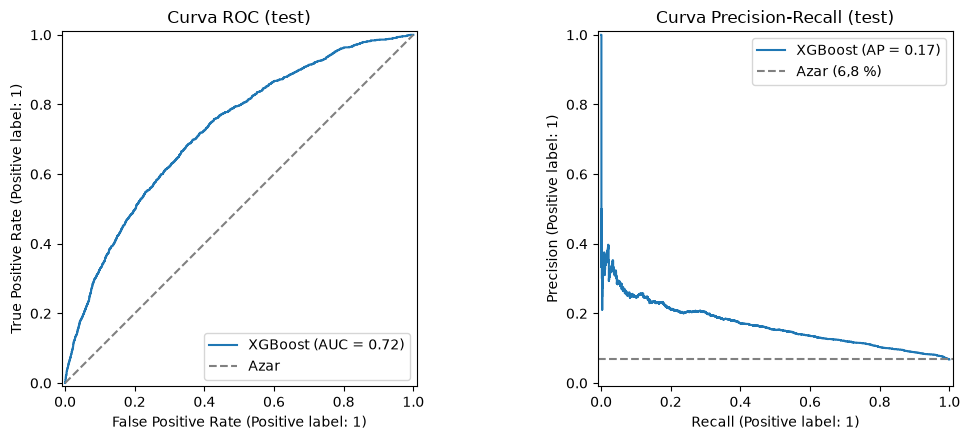

In [75]:
# Graficas de ROC y PR

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

y_arr = np.asarray(y_test)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

RocCurveDisplay.from_predictions(y_arr, proba_test, ax=ax[0], name="XGBoost")
ax[0].plot([0, 1], [0, 1], "--", color="gray", label="Azar")
ax[0].set_title("Curva ROC (test)")
ax[0].legend()

PrecisionRecallDisplay.from_predictions(y_arr, proba_test, ax=ax[1], name="XGBoost")
ax[1].axhline(y_arr.mean(), linestyle="--", color="gray", label="Azar (6,8 %)")
ax[1].set_title("Curva Precision-Recall (test)")
ax[1].legend()

plt.tight_layout()
plt.savefig("../docs/img/curvas_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Nivel de riesgo

orden = np.argsort(-proba_test)          # de mas a menos riesgoso
y_orden = y_arr[orden]

for pct in [0.05, 0.10, 0.20, 0.30]:
    k = int(len(y_orden) * pct)
    capturadas = y_orden[:k].sum() / y_arr.sum()
    print(f"Revisando el {pct:.0%} más riesgoso: capturás {capturadas:.1%} de las tardes")

Revisando el 5% más riesgoso: capturás 17.0% de las tardes
Revisando el 10% más riesgoso: capturás 29.9% de las tardes
Revisando el 20% más riesgoso: capturás 47.1% de las tardes
Revisando el 30% más riesgoso: capturás 60.0% de las tardes


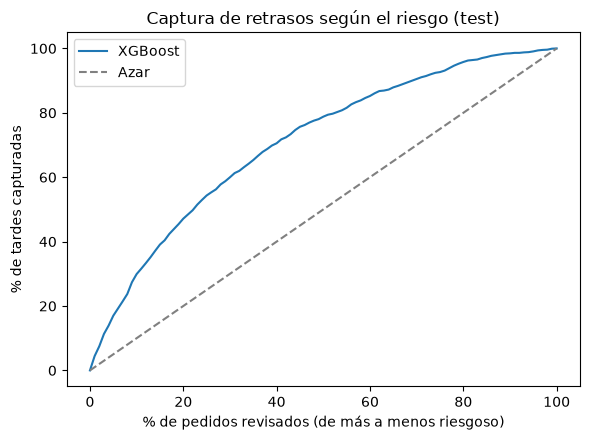

In [77]:
# Grafica del nivel de riesgo

pcts = np.linspace(0, 1, 101)
captura = [y_orden[:int(len(y_orden) * p)].sum() / y_arr.sum() for p in pcts]

plt.figure(figsize=(6, 4.5))
plt.plot(pcts * 100, np.array(captura) * 100, label="XGBoost")
plt.plot([0, 100], [0, 100], "--", color="gray", label="Azar")
plt.xlabel("% de pedidos revisados (de más a menos riesgoso)")
plt.ylabel("% de tardes capturadas")
plt.title("Captura de retrasos según el riesgo (test)")
plt.legend()
plt.tight_layout()
plt.savefig("../docs/img/captura_riesgo.png", dpi=150, bbox_inches="tight")
plt.show()